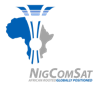 &nbsp;&nbsp; 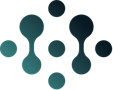

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Publica-AI/nigcomsat-ai-developer/blob/jasons-restructure/Jasons-Restructure/week-1/day-1-colab-and-your-first-time-series/4-instructor-only/W1D1-solution.ipynb)

> 🧑🏾‍🏫 **INSTRUCTOR SOLUTION.** Every blank is filled in. Don't share this with participants before the session ends.

# 🛰️ Week 1 · Day 1: Colab Bootcamp + Your First Time Series

**Today:** learn to drive Google Colab, then load three years of Ka-band link data and find the rainy season *yourself*.

| Symbol | Means |
|---|---|
| 📖 | Read this |
| ▶️ | Run the cell below (click it, then press **Shift + Enter**) |
| ✍️ | Your turn: replace every `___` with your answer |
| ✅ / ❌ | The check tells you if you got it right, with a hint if not |
| 🌶️ | Bonus task for fast finishers |

> ## ⚠️ Do this FIRST: **File → Save a copy in Drive**
> If you skip this, your work disappears when you close the tab. Your copy opens in a new tab: work there.

**Rule book:** keep `W1D1-rulebook.pdf` open next to you. It lists every step and every common error with its fix.

## ▶️ STEP 0: Set up (run this once, every time you open the notebook)

Click the cell below and press **Shift + Enter** (or click the ▶ on its left). It prepares Python and the answer checker.
You should see `✅ Ready!`. If Colab warns *"This notebook was not authored by Google"*, click **Run anyway**: that's normal.

In [ ]:
#@title 🚀 STEP 0 · Run me first (click the ▶ button on the left of this cell) { display-mode: "form" }
import sys, warnings
warnings.filterwarnings("ignore")
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from pathlib import Path
from urllib.request import urlretrieve

pd.set_option("display.width", 130)
pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.figsize": (11, 3.6), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .25, "axes.titleweight": "bold",
                     "axes.prop_cycle": plt.cycler(color=["#0A5DB4", "#C77700", "#008C7E"])})

IN_COLAB = "google.colab" in sys.modules
RAW = "https://raw.githubusercontent.com/Publica-AI/nigcomsat-ai-developer/main/Time-series"
DATA_HOME = {'additive_multiplicative_demo': 'week-03', 'bandwidth_throughput_daily': 'week-03', 'ka_band_availability_daily': 'week-03', 'ka_band_availability_monthly': 'week-03', 'link_margin_hourly_aug2025': 'week-03', 'noc_tickets_daily': 'week-03', 'noc_tickets_weekly': 'week-03', 'transponder_utilisation_monthly': 'week-03', 'vsat_uptime_by_region_weekly': 'week-03', 'rf_link_quality_hourly': 'week-03', 'bus_power_telemetry_hourly': 'week-04', 'battery_health_daily': 'week-04', 'twta_thermal_daily': 'week-04', 'telemetry_anomaly_labels': 'week-04', 'bus_telemetry_multivariate_hourly': 'week-05', 'anomaly_labels_week5': 'week-05', 'degradation_assets_daily': 'week-06', 'degradation_thresholds': 'week-06', 'ops_tickets_weekly': 'week-06'}

def data_path(name, week=None):
    """Download a course CSV once and return where it is saved.
    week: which original folder to use, e.g. "week-03" (two files exist in both week-03 and week-04).
    If you uploaded the file yourself (Files panel), that copy is used instead."""
    uploaded = Path(f"{name}.csv")
    if uploaded.exists():
        return uploaded
    week = week or DATA_HOME[name]
    local = Path("course_data") / week / f"{name}.csv"
    if not local.exists():
        local.parent.mkdir(parents=True, exist_ok=True)
        urlretrieve(f"{RAW}/{week}/data/{name}.csv", local)
    return local

def load_labels(name="telemetry_anomaly_labels", week=None):
    """Read an answer-key (labels) file. The original telemetry_anomaly_labels.csv has a stray comma
    inside one description, which makes pd.read_csv crash, so the last column is read as free text."""
    lines = Path(data_path(name, week)).read_text(encoding="utf-8").splitlines()
    cols = lines[0].split(",")
    rows = [ln.split(",", len(cols) - 1) for ln in lines[1:] if ln.strip()]
    df = pd.DataFrame(rows, columns=cols)
    for c in ("start", "end"):
        if c in df:
            df[c] = pd.to_datetime(df[c], format="mixed")
    return df

___ = None          # this is "the blank". Replace every ___ with your answer.
SCORE = {}

def _blank(x):
    return x is None or (isinstance(x, tuple) and any(v is None for v in x))

def check(task, answer):
    """Marks one task. Prints ✅ or ❌ with a hint."""
    if _blank(answer):
        print("✍️  Fill in the blank first: replace ___ with your answer, then run the cell again.")
        return
    try:
        ok, good, hint = CHECKS[task](answer)
    except Exception as e:
        ok, good, hint = False, "", f"{HINTS.get(task, 'Read the task again.')}  (Python said: {type(e).__name__})"
    SCORE[task] = ok
    print(("✅ " + good) if ok else ("❌ Not yet. Hint: " + hint))

def scoreboard():
    got = sum(SCORE.values())
    print(f"You have {got} of {len(CHECKS)} tasks correct.")
    print("🏆 Oya, you don finish! Mad o!" if got == len(CHECKS) else "💪 Keep going: scroll up and fix the ❌ ones.")

# ---- today's checks ----
def _ka():
    return pd.read_csv(data_path("ka_band_availability_daily"), parse_dates=["timestamp"], index_col="timestamp").asfreq("D")

def _c_a2(x):
    return int(x) == 8760, "8,760 hours in a year. That is how many rows an hourly sensor makes every year!", "24 hours × 365 days."

def _c_b1(x):
    return str(x).strip().lower() in {"text", "string", "str", "object"}, \
        "Correct: pandas read the dates as plain TEXT. It does not yet know they are dates.", \
        "Look at the dtype printed next to timestamp. Is it a number, a date, or text?"

def _c_b2(x):
    return x == "timestamp", "Yes! The time column is called \"timestamp\".", \
        "Look at the column names in the table above. Remember the quotes: \"...\""

def _c_b3(x):
    return int(x) == len(_ka()), f"{len(_ka()):,} days. Three full years (2024 was a leap year: 365 + 366 + 365).", \
        "Use len(ka) to count the rows."

def _c_b4(x):
    k = _ka(); first, last = pd.Timestamp(x[0]), pd.Timestamp(x[1])
    return (first == k.index.min()) and (last == k.index.max()), \
        f"From {k.index.min().date()} to {k.index.max().date()}.", "Try ka.index.min() and ka.index.max()."

def _c_b5(x):
    return int(x) == 3, "3 missing days found! Without .asfreq() they were invisible.", \
        "After .asfreq(\"D\"), count the empty values with .isna().sum()."

def _c_b6(x):
    t = pd.Timestamp(x)
    return t == _ka()["availability_pct"].idxmin(), \
        f"{t.date()}: in July, right in the rainy season. That's Ka-band rain fade. 🌧️", \
        "Use ka[\"availability_pct\"].idxmin(): it returns the DATE of the smallest value."

def _c_b7(x):
    return isinstance(x, str) and len(x.strip()) >= 15 and x.strip().lower() not in {"my chart", "chart", "title"}, \
        "Nice: a title that states a finding beats a title that just names the data.", \
        "Write a sentence of at least 15 characters that says what the chart SHOWS."

def _c_b8(x):
    return str(x).strip().lower() in {"august", "aug", "8"}, "August! Peak rainy season = lowest availability.", \
        "Find the month with the lowest bar in the monthly chart."

def _c_b9(x):
    want = ("seasonality", "trend", "noise", "cycle")
    got = tuple(str(v).strip().lower() for v in x)
    wrong = [i + 1 for i, (g, w) in enumerate(zip(got, want)) if g != w]
    return not wrong, "All four correct. You can now name the 4 characters in any series.", \
        f"Check statement(s) {wrong}. Choose from: trend, seasonality, cycle, noise."

def _c_b10(x):
    return int(x) == 22, "22:00 in Lagos (WAT = UTC + 1). The eclipse happens around Nollywood-movie time. 🎬", \
        "WAT is UTC plus ONE hour."

def _c_bonus(x):
    return str(x).strip().lower() == "sunday", "Sunday! Even faults rest on Sunday. You'll use this on Day 3. 😄", \
        "Look at the averages by day name. Which is smallest?"

CHECKS = {"A2": _c_a2, "B1": _c_b1, "B2": _c_b2, "B3": _c_b3, "B4": _c_b4, "B5": _c_b5, "B6": _c_b6,
          "B7": _c_b7, "B8": _c_b8, "B9": _c_b9, "B10": _c_b10, "BONUS": _c_bonus}
HINTS = {"B4": "Give two dates, e.g. first_day = ka.index.min()", "B6": "idxmin() gives the date of the minimum."}

print(f"✅ Ready! pandas {pd.__version__} · running in {'Google Colab' if IN_COLAB else 'Jupyter'}. Scroll down and let's go 🚀")


---
# Part A: Colab warm-up (15 min) 💻

### A1 ▶️ Your first cell
Click the cell below and press **Shift + Enter**. Then change the message to include your name and run it again.

In [ ]:
print("Hello from NIGCOMSAT! 🛰️")

### A2 ✍️ Colab is a calculator too
An **hourly** sensor sends one reading every hour. How many readings does it send in one (non-leap) year?
Replace `___` with a Python calculation (hint: hours in a day × days in a year).

In [ ]:
hours_in_year = 24 * 365

check("A2", hours_in_year)

### A3 🧠 Colab's short memory (try it!)
1. Run the cell below: it prints `hours_in_year`.
2. Now go to the menu **Runtime → Restart session**, click **Yes**.
3. Run the cell below again. You get a **`NameError`**. That means *"I forgot. Run the cells above again."*
4. Fix it: run **STEP 0** and **A2** again, then this cell. ✅

> 💡 **Remember:** after every restart, run STEP 0 first.

In [ ]:
print(hours_in_year)

### A4 📖 Text cells
This cell is a **text cell**. Double-click it to see how it's written, then press **Shift + Enter** to make it pretty again.
Try it: double-click here and add your name after the arrow 👉

### A5 📖 Where the files live
Click the **📁 folder icon** on the left edge of Colab. That's the *Files panel*. The data files you download today will appear there.
Want to use your own CSV later? Drag it into the Files panel (or click the upload icon). It disappears when the session ends, so keep the original on your laptop.

---
# Part B: Your first time series (45 min) ⏱️

**The data:** `ka_band_availability_daily.csv`: for every day of 2023–2025, the percentage of the day the **Ka-band Nigeria spot beam** was working properly.
It's synthetic teaching data, built to behave like NigComSat-1R, so it's safe to use with AI tools.

### B1 ▶️ Load it the *naive* way and look
Run the cell. `head()` shows the first 5 rows; `dtypes` shows the TYPE pandas gave each column.

In [ ]:
ka_raw = pd.read_csv(data_path("ka_band_availability_daily"))

display(ka_raw.head())
print(ka_raw.dtypes)

✍️ Look at the type next to `timestamp`. Does pandas think it's a **date** or plain **text**? (`object` or `str` means text.)
Type `"date"` or `"text"` (with the quotes).

In [ ]:
timestamp_type = "text"

check("B1", timestamp_type)

### B2 ✍️ Teach pandas about time
Our 3-line recipe needs the **name of the time column**. Write it in quotes. The next cell uses it.

In [ ]:
TIME_COLUMN = "timestamp"

check("B2", TIME_COLUMN)

▶️ Now the recipe: **parse_dates** (text → dates), **index_col** (time becomes the row label), **.asfreq("D")** (one row per day, so gaps can't hide).

In [ ]:
assert TIME_COLUMN is not None, "✍️ Do B2 first: fill in TIME_COLUMN above, then run this cell again."

ka = pd.read_csv(data_path("ka_band_availability_daily"),
                 parse_dates=[TIME_COLUMN],
                 index_col=TIME_COLUMN)
ka = ka.asfreq("D")

ka.head()

### B3 ✍️ How many days of data?
`len(something)` counts rows.

In [ ]:
n_days = len(ka)

check("B3", n_days)

### B4 ✍️ First and last day
The dates are now the **index**. `ka.index.min()` gives the earliest one. What gives the latest?

In [ ]:
first_day = ka.index.min()
last_day = ka.index.max()

check("B4", (first_day, last_day))

### B5 ✍️ Catch the hidden gap 🕵🏾
Real exports lose rows. Below we **pretend** an export glitch deleted three days in March 2024.
`len()` says it's fine… but is it? Fill in the frequency code for **daily** (look at the recipe in B2!). The cell then re-declares the rhythm and counts the empty cells with `.isna().sum()`.

In [ ]:
broken = ka.drop(pd.to_datetime(["2024-03-06", "2024-03-07", "2024-03-08"]))
print("rows in the broken export:", len(broken), " <- looks normal, right?")

In [ ]:
FREQ = "D"          # the code for "daily", in quotes
fixed = broken.asfreq(FREQ) if FREQ else broken
missing_days = fixed["availability_pct"].isna().sum()
print("missing days revealed:", missing_days)

check("B5", missing_days)

### B6 ✍️ The worst day in three years
`.idxmin()` returns the **date** (the index) where a column is smallest. Find the worst day for `availability_pct`.

In [ ]:
worst_day = ka["availability_pct"].idxmin()

if worst_day is not None:
    print(worst_day, "→", ka.loc[worst_day, "availability_pct"], "%")
check("B6", worst_day)

### B7 ✍️ Draw it, with a title that tells the STORY
A bad title names the data (*"Availability"*). A good title states the finding (*"Availability dips every rainy season"*).
Run it first, look at the chart, then write your own title sentence.

In [ ]:
my_title = "Ka-band availability dips every rainy season, worst in July–August"

ka["availability_pct"].plot(title=my_title, lw=1)
plt.ylabel("% of day link was OK")
plt.show()

check("B7", my_title)

### B8 ✍️ Which month is worst on average?
▶️ Run the first cell: it averages each calendar month across the 3 years and draws a bar chart. Then answer with the month's **name**.

In [ ]:
by_month = ka["availability_pct"].groupby(ka.index.month).mean()
by_month.index = ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"]
by_month.plot(kind="bar", title="Average availability by calendar month (2023–2025)", ylim=(97.5, 100))
plt.show()

In [ ]:
worst_month = "August"

check("B8", worst_month)

### B9 ✍️ Name the character
Every series is built from **trend**, **seasonality**, **cycle** and **noise**. Which one is each statement?

1. Ka-band availability drops **every August** during the rainy season.
2. The VSAT network **keeps growing** year after year.
3. NOC tickets went from **38 last week to 41 this week**.
4. Capacity demand was strong for two years, weak for three, and is now rising again (**no fixed length**).

In [ ]:
s1 = "seasonality"
s2 = "trend"
s3 = "noise"
s4 = "cycle"

check("B9", (s1, s2, s3, s4))

### B10 ✍️ Time zones
The satellite's eclipse happens at **21:00 UTC**. What hour is that on a Lagos clock (WAT = UTC + 1)? Give just the hour as a number.

In [ ]:
eclipse_hour_lagos = 22

check("B10", eclipse_hour_lagos)

---
## 🌶️ Pepper task (bonus): a new file, all by yourself
Load `noc_tickets_daily` (time column: `date`) using the same 3-line recipe, then average `tickets_raised` by **day name**.
Which day of the week has the **fewest** tickets? Type the day's name.

In [ ]:
tk = pd.read_csv(data_path("noc_tickets_daily"), parse_dates=["date"], index_col="date").asfreq("D")

display(tk.groupby(tk.index.day_name())["tickets_raised"].mean().round(2).sort_values())

quietest_day = "Sunday"
check("BONUS", quietest_day)

---
## 🏁 Finish line
▶️ Run the scoreboard. Then **File → Save** (your copy is in Google Drive → *Colab Notebooks*).

In [ ]:
scoreboard()

### 📝 What you learned today
- **Colab:** save a copy, run top to bottom, restart when confused, run STEP 0 after every restart.
- **A time series** is a table where the **order of rows carries information**: timestamp + value + cadence.
- **The recipe:** `parse_dates` → `index_col` → `.asfreq()` so missing periods show up as `NaN` instead of hiding.
- **Inspect before you trust:** rows, range, gaps, duplicates, missing values.
- **The 4 characters:** trend, seasonality, cycle, noise.

**Next time:** *Charts That Don't Lie*: how a daily **average** hid a whole rain outage. 🌧️

<sub>Data: synthetic teaching datasets from the original Week 3 code book (`Time-series/week-03`). They are safe to use in AI assistants. Real NIGCOMSAT data is not.</sub>